# Slide-tags human tonsil: input data

Russell et al., *Nature* 2024 ([Single Cell Portal SCP2169](https://singlecell.broadinstitute.org/single_cell/study/SCP2169)).
Download the tonsil files into `DATA / "tonsil"`:
- `expression/<id>/{matrix.mtx.gz, features.tsv.gz, barcodes.tsv.gz}`: raw counts
- `expression/HumanTonsil_expression.csv.gz`: the authors' processed matrix (only its gene names are used)
- `cluster/HumanTonsil_spatial.csv`: spatial coordinates and cell types
- `metadata/HumanTonsil_metadata.csv`: donor and sample metadata

Steps:
1. Raw counts for the cells the authors annotated, restricted to the genes of their processed matrix, then genes in fewer than 10 cells removed.
2. Tissue regions: KMeans (k = 3) on the niche cell-type composition.
3. 10,000-HVG panel (seurat_v3 on the raw counts), the input of every model.
4. Spatial maps of the cell types and regions.

Outputs: `tonsil_fullgenes.h5ad` and `tonsil_nl_10000hvg.h5ad` in `DATA`, figures in `slidetags_tonsil/figures/tonsil_10000hvg/`.
The baselines write their embeddings into `tonsil_nl_10000hvg.h5ad`, so run this notebook before `tonsil/run_panel.sh`.

In [1]:
import gzip
import os
from pathlib import Path

import anndata as ad
import colorcet as cc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import scipy.sparse as sp
import scvi
from sklearn.cluster import KMeans

plt.rcParams["svg.fonttype"] = "none"

DATA = Path("/home/nathanl/Data/slidetags")
RAW = DATA / "tonsil"
PREFIX = "HumanTonsil"
N_HVG = 10000
FIGURES_FOLDER = "/home/nathanl/scviva_paper/slidetags_tonsil/figures/tonsil_10000hvg/"
os.makedirs(FIGURES_FOLDER, exist_ok=True)


def read_scp_csv(path):
    """Single Cell Portal CSV: header row, then a 'TYPE' row to skip."""
    df = pd.read_csv(path, index_col=0)
    if str(df.index[0]).upper() == "TYPE":
        df = df.iloc[1:]
    return df

In [2]:
sc.settings._vector_friendly = True
# Set SVG font type to 'none' to keep text as text in SVG files
plt.rcParams["svg.fonttype"] = "none"

## 1. Raw counts

In [3]:
# raw counts: 10x matrix market files, genes x cells
mtx_path = next((RAW / "expression").rglob("matrix.mtx.gz"))
with gzip.open(mtx_path, "rb") as f:
    M = scipy.io.mmread(f)
features = pd.read_csv(mtx_path.parent / "features.tsv.gz", sep="\t", header=None, names=["gene_id", "gene_symbol", "feature_type"])
barcodes = pd.read_csv(mtx_path.parent / "barcodes.tsv.gz", sep="\t", header=None)[0].values
adata = ad.AnnData(
    X=sp.csr_matrix(M.T),
    obs=pd.DataFrame(index=pd.Index(barcodes, name="cell_id")),
    var=features.set_index("gene_symbol"),
)
adata.var_names_make_unique()

spatial = read_scp_csv(RAW / "cluster" / f"{PREFIX}_spatial.csv")
meta = read_scp_csv(RAW / "metadata" / f"{PREFIX}_metadata.csv")

# cells: the barcodes the authors annotated
keep = [b for b in spatial.index if b in set(adata.obs_names)]
adata = adata[keep].copy()
spatial, meta = spatial.loc[keep], meta.loc[keep]

# genes: those of the authors' processed matrix (its first column), then a min_cells filter
with gzip.open(RAW / "expression" / f"{PREFIX}_expression.csv.gz", "rt") as f:
    next(f)
    processed_genes = {line.split(",", 1)[0].strip().strip('"') for line in f}
adata = adata[:, [g for g in adata.var_names if g in processed_genes]].copy()
sc.pp.filter_genes(adata, min_cells=10)

adata.obs["cell_type"] = pd.Categorical(spatial["cell_type"].astype(str).values)
for col in ["biosample_id", "donor_id", "species__ontology_label", "disease__ontology_label",
            "organ__ontology_label", "library_preparation_protocol__ontology_label", "sex"]:
    if col in meta.columns:
        adata.obs[col.replace("__ontology_label", "")] = pd.Categorical(meta[col].astype(str).values)
adata.obs["dataset"] = pd.Categorical(["tonsil"] * adata.n_obs)
adata.obs["sample_id"] = adata.obs["dataset"]
adata.obs["tissue"] = pd.Categorical(["palatine tonsil"] * adata.n_obs)
adata.obsm["spatial"] = spatial[["X", "Y"]].astype(float).values

adata.layers["counts"] = adata.X.copy()
adata.obs["total_counts"] = np.asarray(adata.layers["counts"].sum(1)).ravel()
adata.obs["n_genes"] = np.asarray((adata.layers["counts"] > 0).sum(1)).ravel()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

/home/nathanl/miniforge3/envs/scvi/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 5778 × 23563
    obs: 'cell_type', 'biosample_id', 'donor_id', 'species', 'disease', 'organ', 'library_preparation_protocol', 'sex', 'dataset', 'sample_id', 'tissue', 'total_counts', 'n_genes'
    var: 'gene_id', 'feature_type', 'n_cells'
    uns: 'log1p'
    obsm: 'spatial'
    layers: 'counts'

## 2. Tissue regions

KMeans (k = 3) on the niche cell-type composition of each cell: the cell-type proportions among its 20 nearest
spatial neighbours (per donor). The clusters are named from their mean composition (table below).

In [4]:
_tmp = adata.copy()
_tmp.obsm["_expression"] = np.zeros((_tmp.n_obs, 1), dtype=np.float32)  # the niche composition does not use it
scvi.external.SCVIVA.preprocessing_anndata(
    _tmp,
    k_nn=20,
    sample_key="donor_id",
    labels_key="cell_type",
    cell_coordinates_key="spatial",
    expression_embedding_key="_expression",
    expression_embedding_niche_key="_expression_niche",
    niche_composition_key="neighborhood_composition",
    niche_indexes_key="niche_indexes",
    niche_distances_key="niche_distances",
)
composition = _tmp.obsm["neighborhood_composition"]
niche_cluster = KMeans(n_clusters=3, random_state=42).fit_predict(composition)
composition.groupby(niche_cluster).mean().T.round(2)

Saved niche_indexes and niche_distances in adata.obsm

Saved neighborhood_composition in adata.obsm

Saved _expression_niche in adata.obsm

,0,1,2
T_CD4,0.36,0.02,0.06
plasma,0.02,0.08,0.03
B_germinal_center,0.09,0.66,0.07
B_naive,0.12,0.04,0.48
B_memory,0.10,0.02,0.17
mDC,0.06,0.00,0.02
T_follicular_helper,0.02,0.09,0.03
NK,0.06,0.01,0.02
FDC,0.04,0.05,0.04
T_CD8,0.07,0.01,0.05


In [5]:
REGION_NAMES = {0: "T_zone", 1: "germinal_center", 2: "mantle_zone"}
adata.obs["region"] = pd.Categorical(pd.Series(niche_cluster).map(REGION_NAMES).values)
print(adata.obs["region"].value_counts())

adata.write_h5ad(DATA / "tonsil_fullgenes.h5ad")
print("tonsil_fullgenes.h5ad", adata.shape)

region
germinal_center    2419
T_zone             1704
mantle_zone        1655
Name: count, dtype: int64
tonsil_fullgenes.h5ad (5778, 23563)


## 3. 10,000-HVG panel

In [6]:
panel = adata.copy()
sc.pp.highly_variable_genes(panel, n_top_genes=N_HVG, flavor="seurat_v3", layer="counts", subset=True)
panel.X = panel.layers["counts"].copy()
sc.pp.normalize_total(panel, target_sum=1e4)
sc.pp.log1p(panel)

panel.write_h5ad(DATA / f"tonsil_nl_{N_HVG}hvg.h5ad")
print(f"tonsil_nl_{N_HVG}hvg.h5ad", panel.shape)

tonsil_nl_10000hvg.h5ad (5778, 10000)


## 4. Spatial maps

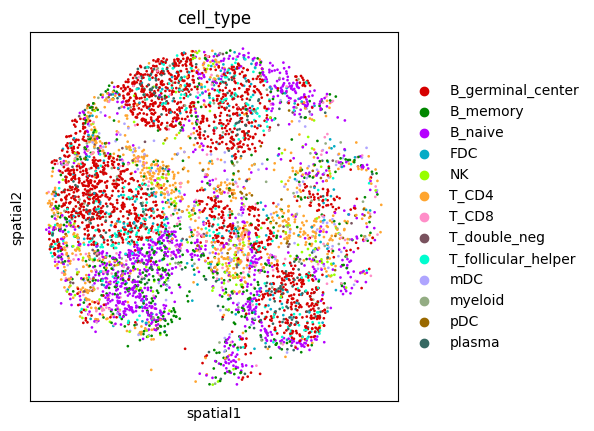

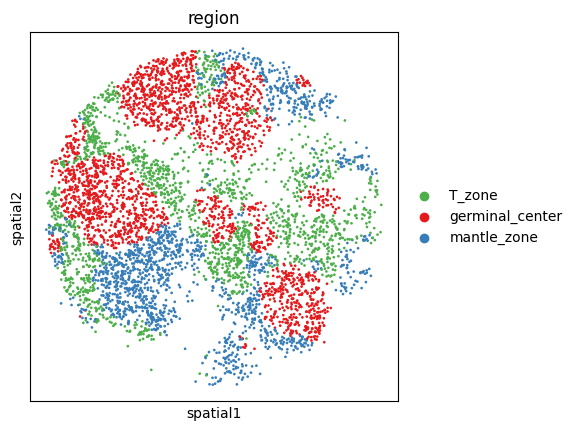

In [7]:
# same colours as the UMAPs of tonsil/tonsil_10000hvg.ipynb
CT_PALETTE = dict(zip(adata.obs["cell_type"].cat.categories, cc.glasbey_light))
REGION_PALETTE = {"T_zone": "#4daf4a", "germinal_center": "#e41a1c", "mantle_zone": "#377eb8"}

for color, palette, name in [
    ("cell_type", CT_PALETTE, "tonsil_spatial_cell_types"),
    ("region", REGION_PALETTE, "tonsil_spatial_regions"),
]:
    sc.pl.embedding(adata, basis="spatial", color=color, palette=palette, size=15, frameon=True, title=color, show=False)
    plt.gca().set_aspect("equal")
    for ext in ("svg", "png"):
        plt.savefig(f"{FIGURES_FOLDER}{name}.{ext}", bbox_inches="tight", dpi=500)
    plt.show()